# **Phase 1 — Data Understanding (Practical)**
---
Sab se pehle hum dataset ko samjhenge. Abhi CNN ya Streamlit par nahi jayenge, kyun ke ek AI Engineer ko model banane se pehle data verify karna chahiye.

## Step 1: MNIST dataset load karein
Apne notebook mein yeh code run karein:

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Dataset load karein
(train_images , train_labels) , (test_images , test_labels) = (tf.keras.datasets.mnist.load_data())
print(f"Tensorflow Version {tf.__version__}")
print(f"Training Images Shape {train_images.shape}")
print(f"Training Labels {train_labels.shape}")
print(f"Test Images {test_images.shape}")
print(f"Test Labels {test_labels.shape}")


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Tensorflow Version 2.21.0
Training Images Shape (60000, 28, 28)
Training Labels (60000,)
Test Images (10000, 28, 28)
Test Labels (10000,)


### **Why?**
 Hum verify kar rahe hain ke dataset successfully load hua aur images aur labels ki dimensions expected hain.

## Step 2: Images aur labels inspect karein

### Is code ka WHY
- plt.subplots(2, 5) 2 rows aur 5 columns ka layout banata hai.
- axes.flat tamam 10 plotting areas par loop chalata hai.
- train_images[i] ek image select karta hai.
- train_labels[i] us image ka actual label show karta hai.
- cmap="gray" image ko grayscale mein display karta hai.
- ax.axis("off") axes aur tick marks hide karta hai.

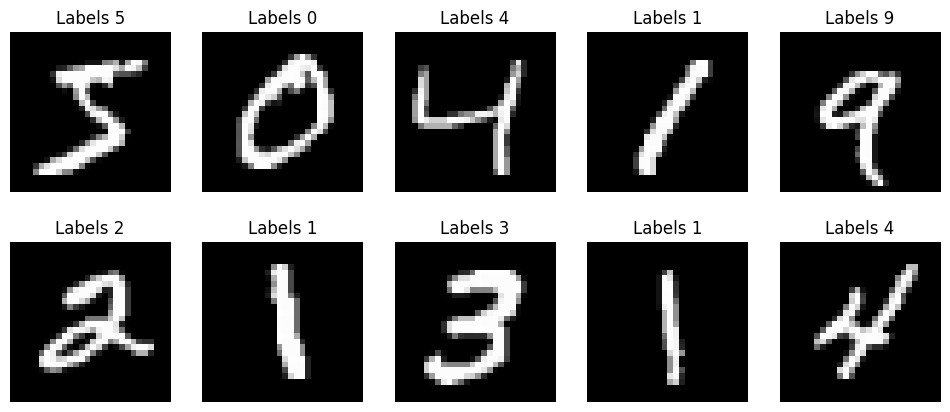

In [ ]:
# Pehli 10 images aur unke labels
fig , axes = plt.subplots(2 , 5 , figsize=(12 , 5))

for i , ax in enumerate(axes.flat):
  ax.imshow(train_images[i] , cmap="gray")
  ax.set_title(f"Labels {train_labels[i]}")
  ax.axis("off")

### AI Engineer ka WHY
Aapne verify kiya ke:
- Raw numerical data meaningful images bana raha hai.
- Labels image ke actual digits se match kar rahe hain.
- Handwritten digits ke shapes aur writing styles mein variation hai.
Real-world projects mein isi tarah data ko visually inspect karte hain, kyun ke incorrect labels model ki learning ko affect kar sakte hain.

## Step 3: Class Distribution Analysis
Ab hum check karenge ke har digit — 0 se 9 — ki training dataset mein kitni images hain.
Yeh kyun important hai? Agar kisi class ki examples bohat kam hon, to model us class ko theek se learn nahi kar sakta. Is problem ko class imbalance kehte hain.

Digit 0: 5923 images
Digit 1: 6742 images
Digit 2: 5958 images
Digit 3: 6131 images
Digit 4: 5842 images
Digit 5: 5421 images
Digit 6: 5918 images
Digit 7: 6265 images
Digit 8: 5851 images
Digit 9: 5949 images


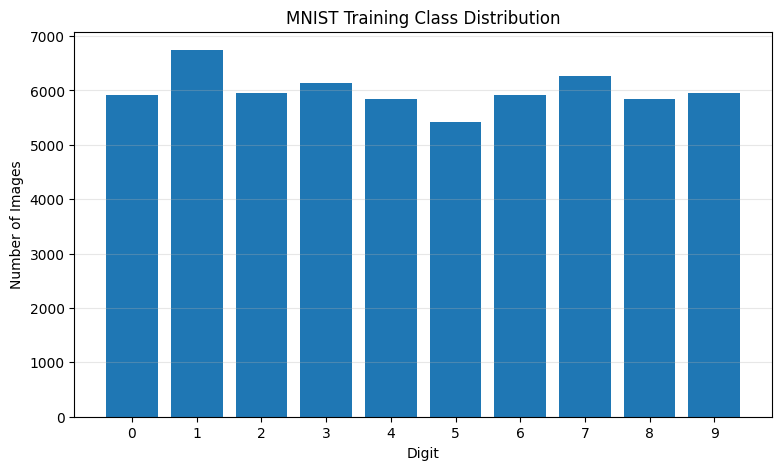

In [ ]:

# Har digit ki images count karein
unique_digits, counts = np.unique(
    train_labels,
    return_counts=True
)

# Counts print karein
for digit, count in zip(unique_digits, counts):
    print(f"Digit {digit}: {count} images")

# Bar chart banayein
plt.figure(figsize=(9, 5))
plt.bar(unique_digits, counts)
plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.title("MNIST Training Class Distribution")
plt.xticks(range(10))
plt.grid(axis="y", alpha=0.3)
plt.show()


## Step 4: Pixel Values aur Normalization
Ab hum Phase 1 ka aakhri step complete karenge. Is mein hum dekhenge ke image pixels ki numerical range kya hai aur normalization se kya change aata hai.

In [ ]:

print("Minimum pixel value:", train_images.min())
print("Maximum pixel value:", train_images.max())
print("Training data type:", train_images.dtype)

print("Original image shape:", train_images[0].shape)
print("First image pixel values:")
print(train_images[0][:5, :5])


Minimum pixel value: 0
Maximum pixel value: 255
Training data type: uint8
Original image shape: (28, 28)
First image pixel values:
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]


### Expected output mein aam tor par:
- Minimum pixel value: 0
- Maximum pixel value: 255
- Data type: uint8
- Image shape: (28, 28)
WHY?
Computer image ko numbers ki form mein process karta hai. MNIST mein uint8 ka matlab pixel values unsigned 8-bit integers hain, jo 0 se 255 tak ho sakti hainlues unsigned 8-bit integers hain, jo 0 se 255 tak ho sakti hain.

## Pixel values normalize karein

In [ ]:

# Pixel values ko 0-1 range mein convert karein
train_images = train_images.astype("float32") / 255.0
test_images = test_images.astype("float32") / 255.0

# Verify normalization
print("After normalization:")
print("Minimum:", train_images.min())
print("Maximum:", train_images.max())
print("Data type:", train_images.dtype)

print("Training shape:", train_images.shape)
print("Test shape:", test_images.shape)


After normalization:
Minimum: 0.0
Maximum: 1.0
Data type: float32
Training shape: (60000, 28, 28)
Test shape: (10000, 28, 28)


Is se image ka shape change nahi hota. Sirf pixel values ki numerical scale change hoti hai.
AI Engineer ka WHY: Neural networks ko suitable numerical scales dena optimization ko stable aur efficient bana sakta hai. Lekin normalization khud model ko patterns nahi sikhati; learning training ke waqt hoti hai.

# Phase 2 — Dense Neural Network Baseline
Is phase mein hum apna pehla model train karenge. Baad mein isi result ko CNN ke saath compare karenge.
Baseline ka matlab: Ek simple initial model jiske results ko reference bana kar hum check kar sakein ke doosra model kitni improvement la raha hai.

## Step 1 — Dense model build aur compile karein

In [ ]:

import time

# 1. Dense Neural Network architecture
dense_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# 2. Training configuration
dense_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 3. Model architecture verify karein
dense_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Is model mein kya ho raha hai?
- Input(shape=(28, 28)) model ko input image ka size batata hai.
- Flatten() image ke 784 pixels ko ek vector mein convert karta hai.
- Dense(128, activation="relu") hidden layer mein 128 neurons rakhta hai.
- Dense(10, activation="softmax") 10 digits ke scores deta hai.
- compile() optimizer, loss aur accuracy metric set karta hai.
- summary() layers aur trainable parameters ki details dikhata hai.
WHY 128 neurons? Yeh ek reasonable starting choice hai, koi universal best number nahi. Hum filhaal simple architecture ko baseline bana rahe hain.

## Step 2 — Model train karein

In [ ]:

start_time = time.time()

dense_history = dense_model.fit(
    train_images,
    train_labels,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

dense_training_time = time.time() - start_time

print(f"Training time: {dense_training_time:.2f} seconds")


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8976 - loss: 0.3736 - val_accuracy: 0.9537 - val_loss: 0.1707
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9512 - loss: 0.1722 - val_accuracy: 0.9637 - val_loss: 0.1319
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9639 - loss: 0.1249 - val_accuracy: 0.9717 - val_loss: 0.1014
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9722 - loss: 0.0982 - val_accuracy: 0.9760 - val_loss: 0.0851
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9772 - loss: 0.0789 - val_accuracy: 0.9768 - val_loss: 0.0826
Training time: 10.52 seconds


### Training settings ka WHY
Setting	Maqsad
epochs=5	Model training data par 5 rounds karega
batch_size=128	Har batch mein 128 images process hongi
validation_split=0.1	Training images ka 10% validation ke liye alag hoga
verbose=1	Training progress aur metrics show hongi
Training ke output mein loss, accuracy, val_loss aur val_accuracy nazar aayenge.
- accuracy: Training subset par performance.
- val_accuracy: Validation subset par performance.
- loss: Training errors ko quantify karta hai.
- val_loss: Validation data par loss.
Agar training accuracy barhti rahe lekin validation performance improve hona band ho jaye ya worse ho, to overfitting ka possibility investigate karna chahiye.

## Step 3 — Training aur validation curves

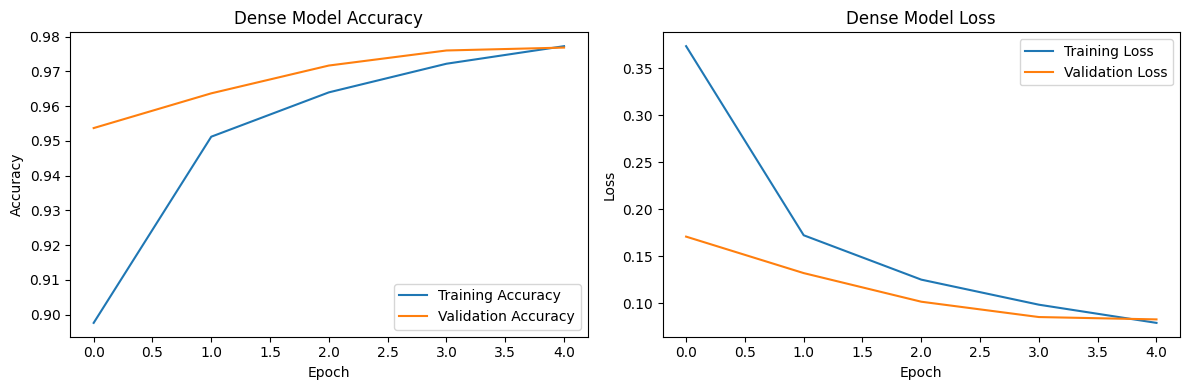

In [ ]:

plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(dense_history.history["accuracy"], label="Training Accuracy")
plt.plot(dense_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Dense Model Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(dense_history.history["loss"], label="Training Loss")
plt.plot(dense_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Dense Model Loss")
plt.legend()

plt.tight_layout()
plt.show()


## Step 4 — Unseen test data par evaluate karein

In [ ]:

dense_test_loss, dense_test_acc = dense_model.evaluate(
    test_images,
    test_labels,
    verbose=0
)

print(f"Dense Test Loss: {dense_test_loss:.4f}")
print(f"Dense Test Accuracy: {dense_test_acc:.4f}")
print(f"Dense Test Accuracy (%): {dense_test_acc * 100:.2f}%")
print(f"Training Time: {dense_training_time:.2f} seconds")


Dense Test Loss: 0.0914
Dense Test Accuracy: 0.9717
Dense Test Accuracy (%): 97.17%
Training Time: 10.52 seconds


## Step 5: CNN Model Build Karna
Ab hum Convolutional Neural Network (CNN) banayenge. CNN images ke spatial patterns, jaise edges, curves aur shapes, seekhne ke liye design kiya gaya hai.

Input data CNN ke liye prepare karein
Aapki images abhi shape (60000, 28, 28) mein hain. CNN ko grayscale channel bhi chahiye, is liye hum ek extra dimension add karenge.

In [ ]:

# CNN ke liye grayscale channel add karein
train_images_cnn = np.expand_dims(train_images, axis=-1)
test_images_cnn = np.expand_dims(test_images, axis=-1)

print("CNN training shape:", train_images_cnn.shape)
print("CNN test shape:", test_images_cnn.shape)


CNN training shape: (60000, 28, 28, 1)
CNN test shape: (10000, 28, 28, 1)


### WHY? CNN ka expected input format hota hai:
(images, height, width, channels)
Yahan channels=1 ka matlab grayscale hai. RGB images mein channels aam tor par 3 hote hain.

## CNN architecture banayein

In [ ]:

cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # Image features learn karna
    tf.keras.layers.Conv2D(
        32, kernel_size=(3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.Conv2D(
        64, kernel_size=(3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Extracted features ko classification ke liye use karna
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## CNN ki layers kyun use ho rahi hain?
- Conv2D: Image mein local patterns aur features learn karta hai.
- MaxPooling2D: Feature maps ka spatial size reduce karta hai aur computation kam karta hai.
- Flatten: Learned feature maps ko vector mein convert karta hai.
- Dense(128): Learned features ki bunyaad par classification karta hai.
- Dense(10): Digits 0–9 ke liye scores deta hai.
Dense baseline ke muqable mein CNN raw pixels ko seedha fully connected hidden layer mein bhejne ke bajaye spatial structure ko preserve karke features extract karta hai.

## CNN train karein

In [ ]:

start_time = time.time()

cnn_history = cnn_model.fit(
    train_images_cnn,
    train_labels,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

cnn_training_time = time.time() - start_time

print(f"CNN training time: {cnn_training_time:.2f} seconds")


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9325 - loss: 0.2302 - val_accuracy: 0.9800 - val_loss: 0.0749
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9807 - loss: 0.0641 - val_accuracy: 0.9853 - val_loss: 0.0485
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9863 - loss: 0.0442 - val_accuracy: 0.9883 - val_loss: 0.0412
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9884 - loss: 0.0355 - val_accuracy: 0.9883 - val_loss: 0.0432
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9912 - loss: 0.0275 - val_accuracy: 0.9898 - val_loss: 0.0337
CNN training time: 19.24 seconds


Hum wahi epochs=5, batch_size=128 aur validation_split=0.1 rakh rahe hain, taake comparison reasonably fair ho. Dono models ki architecture different hai, is liye training time aur learning behaviour bhi different ho sakte hain.

## CNN ko test karein

In [ ]:

cnn_test_loss, cnn_test_acc = cnn_model.evaluate(
    test_images_cnn,
    test_labels,
    verbose=0
)

print(f"CNN Test Loss: {cnn_test_loss:.4f}")
print(f"CNN Test Accuracy: {cnn_test_acc:.4f}")
print(f"CNN Test Accuracy (%): {cnn_test_acc * 100:.2f}%")
print(f"CNN Training Time: {cnn_training_time:.2f} seconds")


CNN Test Loss: 0.0300
CNN Test Accuracy: 0.9908
CNN Test Accuracy (%): 99.08%
CNN Training Time: 19.24 seconds


## Dono models compare karein
Jab CNN ka evaluation complete ho jaye, yeh cell run karein:

In [ ]:

comparison = {
    "Model": ["Dense Neural Network", "CNN"],
    "Test Accuracy (%)": [
        dense_test_acc * 100,
        cnn_test_acc * 100
    ],
    "Test Loss": [
        dense_test_loss,
        cnn_test_loss
    ],
    "Training Time (seconds)": [
        dense_training_time,
        cnn_training_time
    ]
}

import pandas as pd

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))


,Model,Test Accuracy (%),Test Loss,Training Time (seconds)
0,Dense Neural Network,97.17,0.0914,10.5150
1,CNN,99.08,0.0300,19.2434
